# A queda nacional da morosidade alcançou todos os estados?

**Projeto Integrado de Ciência de Dados no Setor Público**  
**Disciplina:** Fundamentos de Ciência de Dados — IDP

## 1. Problema público

A razoável duração do processo é um direito fundamental previsto no art. 5º, inciso LXXVIII, da Constituição Federal. Ainda assim, o tempo necessário para a conclusão de processos varia de forma significativa entre os Tribunais de Justiça estaduais.

A pergunta central deste projeto é: **entre 2015 e 2025, todos os tribunais reduziram o tempo médio até a baixa dos processos não criminais de primeiro grau, ou a melhora foi desigual?**

A análise examina associações e diferenças observadas nos dados, com foco em monitoramento, transparência e accountability, sem buscar causalidade.

## 2. Base de dados

A base utilizada é `base_davi_lemes_ferreira_reduzida.csv`, construída a partir do Justiça em Números, do Conselho Nacional de Justiça (CNJ).

Cada linha representa um **tribunal em um ano**. A variável principal é:

- `tpbaixcncrim1m`: tempo médio, em dias, até a baixa dos processos de conhecimento não criminais no primeiro grau.

Outras variáveis utilizadas:

- `sigla`: identificador do tribunal.
- `ano`: ano de referência.
- `estoque_por_magistrado`: processos pendentes por magistrado.
- `litigiosidade`: casos novos por 100 mil habitantes.
- `despesa_rel`: despesa por processo em relação à média do ano.
- `carga_por_servidor`: processos por servidor.
- `f3`: força de trabalho por 100 mil habitantes.
- `log_h1`: logaritmo da população do estado.

A base reúne 292 observações de 27 tribunais entre 2015 e 2025. O painel não é perfeitamente completo, pois nem todos os tribunais possuem registro em todos os anos.


In [1]:
# Importa as bibliotecas necessárias para leitura, tratamento e visualização dos dados
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configura o formato padrão dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Define o nome do arquivo da base
ARQUIVO = "base_davi_lemes_ferreira_reduzida.csv"

# Lê a base. O separador é ponto e vírgula e o decimal é vírgula.
df = pd.read_csv(ARQUIVO, sep=";", decimal=",")

# Exibe as primeiras linhas para verificar se a leitura foi correta
df.head()

,sigla,ano,tpbaixcncrim1m,estoque_por_magistrado,litigiosidade,despesa_rel,carga_por_servidor,afastamento_por_mag,densidade_demografica,log_h1,f3
0,TJAC,2015,563.0,1416.584906,5383.360319,1.856702,78.471485,31.056604,4.895776,13.596750,250.275976
1,TJAC,2016,448.0,1636.882353,5294.072270,1.904768,84.647295,28.431373,4.976044,13.613012,277.340034
2,TJAC,2017,437.0,1732.530612,5094.386700,1.715505,94.611607,27.693878,5.054839,13.628723,214.676858
3,TJAC,2018,519.0,2106.690476,4349.766757,1.553146,82.977661,50.380952,5.296400,13.675404,214.779153
4,TJAC,2019,440.0,2318.564103,4518.133423,1.559732,77.634684,58.000000,5.373598,13.689875,231.763112


## 3. Preparação dos dados

Nesta etapa, os dados são organizados e verificados. O objetivo é garantir que as variáveis estejam no formato correto e que não existam valores ausentes nas informações essenciais.

A variável `tpbaixcncrim1m` será renomeada para `tempo_baixa`, para facilitar a leitura.


In [2]:
# Renomeia a variável-alvo para um nome mais simples
df = df.rename(columns={"tpbaixcncrim1m": "tempo_baixa"})

# Converte as colunas numéricas, caso algum valor tenha sido lido como texto
colunas_numericas = [
    "ano", "tempo_baixa", "estoque_por_magistrado", "litigiosidade",
    "despesa_rel", "carga_por_servidor", "f3", "log_h1"
]

for coluna in colunas_numericas:
    df[coluna] = pd.to_numeric(df[coluna], errors="coerce")

# Ordena a base por tribunal e ano
df = df.sort_values(["sigla", "ano"]).reset_index(drop=True)

# Verifica dimensões, tribunais, período e valores ausentes
print("Dimensões da base:", df.shape)
print("Tribunais:", df["sigla"].nunique())
print("Período:", df["ano"].min(), "a", df["ano"].max())
print("\nValores ausentes nas colunas principais:")
print(df[["sigla", "ano", "tempo_baixa"]].isna().sum())

Dimensões da base: (292, 11)
Tribunais: 27
Período: 2015 a 2025

Valores ausentes nas colunas principais:
sigla          0
ano            0
tempo_baixa    0
dtype: int64


## 4. Demonstração dos dados

Antes de analisar a queda da morosidade, é necessário entender o comportamento geral do tempo médio até a baixa.

A média pode ser influenciada por valores muito altos ou muito baixos. Por isso, a mediana também será utilizada como medida de posição.


In [3]:
# Estatísticas descritivas do tempo médio até a baixa
df["tempo_baixa"].describe().round(2)

count     292.00
mean      886.18
std       376.74
min       200.64
25%       608.23
50%       859.92
75%      1091.50
max      2438.00
Name: tempo_baixa, dtype: float64

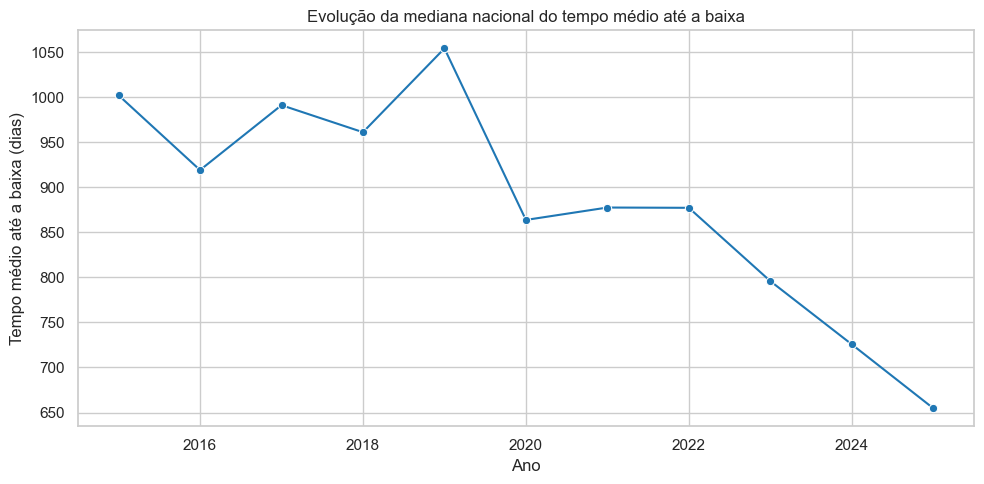

,ano,tempo_baixa
0,2015,1002.0
1,2016,919.0
2,2017,991.0
3,2018,961.0
4,2019,1054.0
5,2020,863.7
6,2021,877.4
7,2022,877.1
8,2023,795.8
9,2024,725.6


In [4]:
# Evolução anual da mediana nacional do tempo de tramitação
evolucao_nacional = (
    df.groupby("ano")["tempo_baixa"]
      .median()
      .reset_index()
)

# Gráfico da evolução nacional
plt.figure(figsize=(10, 5))
sns.lineplot(data=evolucao_nacional, x="ano", y="tempo_baixa", marker="o", color="#1f77b4")
plt.title("Evolução da mediana nacional do tempo médio até a baixa")
plt.xlabel("Ano")
plt.ylabel("Tempo médio até a baixa (dias)")
plt.tight_layout()
plt.show()

# Exibe a tabela usada no gráfico
evolucao_nacional.round(1)

**Leitura inicial:** o gráfico mostra a trajetória nacional, medida pela mediana dos 27 tribunais. Uma queda na linha indica redução geral do tempo de tramitação, mas não informa se todos os tribunais reduziram seus tempos na mesma proporção.

## 5. Abordagem estatística

Para responder à pergunta central, serão calculadas duas medidas para cada tribunal:

1. **Variação absoluta:** diferença, em dias, entre o primeiro e o último ano disponível de cada tribunal.
2. **Variação percentual:** quanto o tempo de tramitação aumentou ou diminuiu em relação ao valor inicial.

A variação percentual é útil porque permite comparar tribunais com níveis iniciais muito diferentes.

Fórmula:

\[\nVariação\ percentual = \frac{Tempo\ final - Tempo\ inicial}{Tempo\ inicial} \times 100
\]


In [5]:
# Seleciona o primeiro e o último ano disponível de cada tribunal
primeiro_ano = (
    df.sort_values("ano")
      .groupby("sigla")
      .first()
      .reset_index()[["sigla", "ano", "tempo_baixa"]]
      .rename(columns={"ano": "ano_inicial", "tempo_baixa": "tempo_inicial"})
)

ultimo_ano = (
    df.sort_values("ano")
      .groupby("sigla")
      .last()
      .reset_index()[["sigla", "ano", "tempo_baixa"]]
      .rename(columns={"ano": "ano_final", "tempo_baixa": "tempo_final"})
)

# Junta as informações iniciais e finais de cada tribunal
variacao = primeiro_ano.merge(ultimo_ano, on="sigla")

# Calcula a variação absoluta, em dias
variacao["variacao_dias"] = variacao["tempo_final"] - variacao["tempo_inicial"]

# Calcula a variação percentual
variacao["variacao_percentual"] = (
    (variacao["tempo_final"] - variacao["tempo_inicial"])
    / variacao["tempo_inicial"]
    * 100
)

# Classifica os tribunais em três grupos
def classifica_variacao(valor):
    if valor < -10:
        return "Redução"
    elif valor > 10:
        return "Aumento"
    else:
        return "Estável"

variacao["situacao"] = variacao["variacao_percentual"].apply(classifica_variacao)

# Ordena pelos tribunais com maior redução percentual
variacao = variacao.sort_values("variacao_percentual").reset_index(drop=True)

# Exibe o resultado
variacao.round(2)

,sigla,ano_inicial,tempo_inicial,ano_final,tempo_final,variacao_dias,variacao_percentual,situacao
0,TJRR,2015,558.0,2025,230.36,-327.64,-58.72,Redução
1,TJMT,2015,1360.0,2025,648.96,-711.04,-52.28,Redução
2,TJPI,2015,1837.0,2025,899.93,-937.07,-51.01,Redução
3,TJTO,2015,1027.0,2025,560.90,-466.10,-45.38,Redução
4,TJGO,2015,1053.0,2025,577.03,-475.97,-45.20,Redução
5,TJAL,2015,1071.0,2025,654.74,-416.26,-38.87,Redução
6,TJSC,2015,979.0,2025,619.48,-359.52,-36.72,Redução
7,TJRJ,2015,1781.0,2025,1129.48,-651.52,-36.58,Redução
8,TJSP,2015,1105.0,2025,701.85,-403.15,-36.48,Redução
9,TJPE,2015,1324.0,2025,855.98,-468.02,-35.35,Redução


C:\Users\t319647\AppData\Local\Temp\ipykernel_20744\818744330.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=contagem, x="Situação", y="Quantidade de tribunais", palette="viridis")


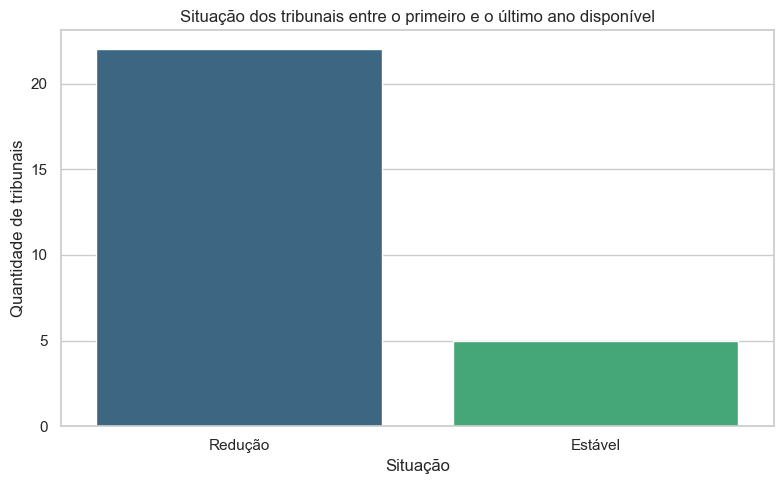

,Situação,Quantidade de tribunais
0,Redução,22
1,Estável,5


In [6]:
# Quantidade de tribunais em cada situação
contagem = variacao["situacao"].value_counts().reset_index()
contagem.columns = ["Situação", "Quantidade de tribunais"]

# Gráfico de barras com a classificação dos tribunais
plt.figure(figsize=(8, 5))
sns.barplot(data=contagem, x="Situação", y="Quantidade de tribunais", palette="viridis")
plt.title("Situação dos tribunais entre o primeiro e o último ano disponível")
plt.xlabel("Situação")
plt.ylabel("Quantidade de tribunais")
plt.tight_layout()
plt.show()

contagem

**Leitura:** a classificação considera redução quando o tempo caiu mais de 10%, aumento quando subiu mais de 10% e estabilidade quando a mudança ficou entre -10% e +10%. Os limites são arbitrários, mas facilitam a comunicação dos resultados.

## 6. Visualização da desigualdade entre tribunais

O gráfico seguinte mostra a variação percentual de cada tribunal. Valores negativos indicam redução do tempo de tramitação; valores positivos indicam aumento.


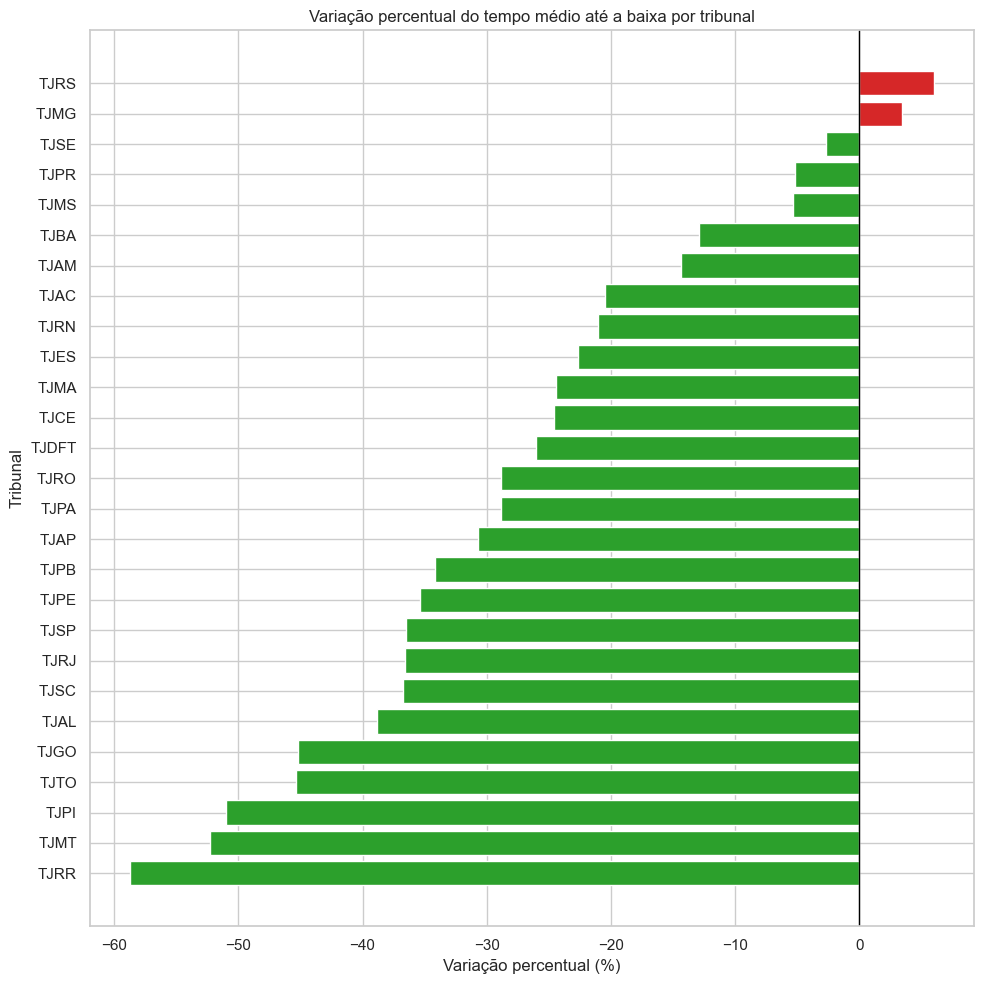

In [7]:
# Gráfico de barras horizontais com a variação percentual por tribunal
plt.figure(figsize=(10, 10))
cores = variacao["variacao_percentual"].apply(
    lambda x: "#2ca02c" if x < 0 else "#d62728"
)

plt.barh(variacao["sigla"], variacao["variacao_percentual"], color=cores)
plt.axvline(0, color="black", linewidth=1)
plt.title("Variação percentual do tempo médio até a baixa por tribunal")
plt.xlabel("Variação percentual (%)")
plt.ylabel("Tribunal")
plt.tight_layout()
plt.show()

**Leitura:** barras verdes indicam redução do tempo médio até a baixa. Barras vermelhas indicam aumento. Mesmo que a mediana nacional tenha caído, é possível que alguns tribunais apresentem aumento ou estabilidade.

## 7. Trajetórias dos tribunais

O gráfico de linhas permite observar se a queda foi generalizada ou concentrada em parte dos tribunais.


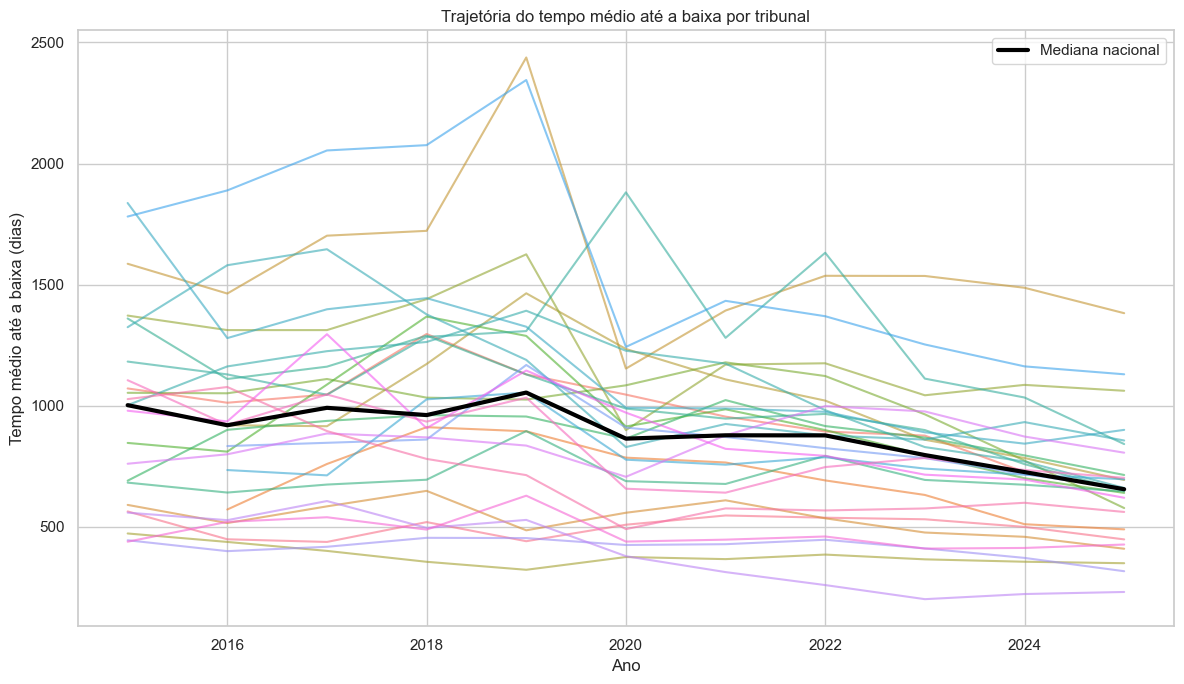

In [8]:
# Gráfico com a trajetória de todos os tribunais
plt.figure(figsize=(12, 7))
sns.lineplot(
    data=df,
    x="ano",
    y="tempo_baixa",
    hue="sigla",
    legend=False,
    alpha=0.6
)

# Adiciona a mediana nacional em destaque
sns.lineplot(
    data=evolucao_nacional,
    x="ano",
    y="tempo_baixa",
    color="black",
    linewidth=3,
    label="Mediana nacional"
)

plt.title("Trajetória do tempo médio até a baixa por tribunal")
plt.xlabel("Ano")
plt.ylabel("Tempo médio até a baixa (dias)")
plt.tight_layout()
plt.show()

**Leitura:** as linhas coloridas representam os tribunais. A linha preta representa a mediana nacional. Se as linhas dos tribunais se afastarem bastante da mediana, isso indica desigualdade entre os estados.

## 8. Tribunais persistentemente acima da mediana

Além da variação inicial-final, é importante verificar se alguns tribunais permaneceram acima da mediana nacional na maior parte do período.

Isso ajuda a distinguir uma oscilação eventual de uma condição persistente de maior morosidade.


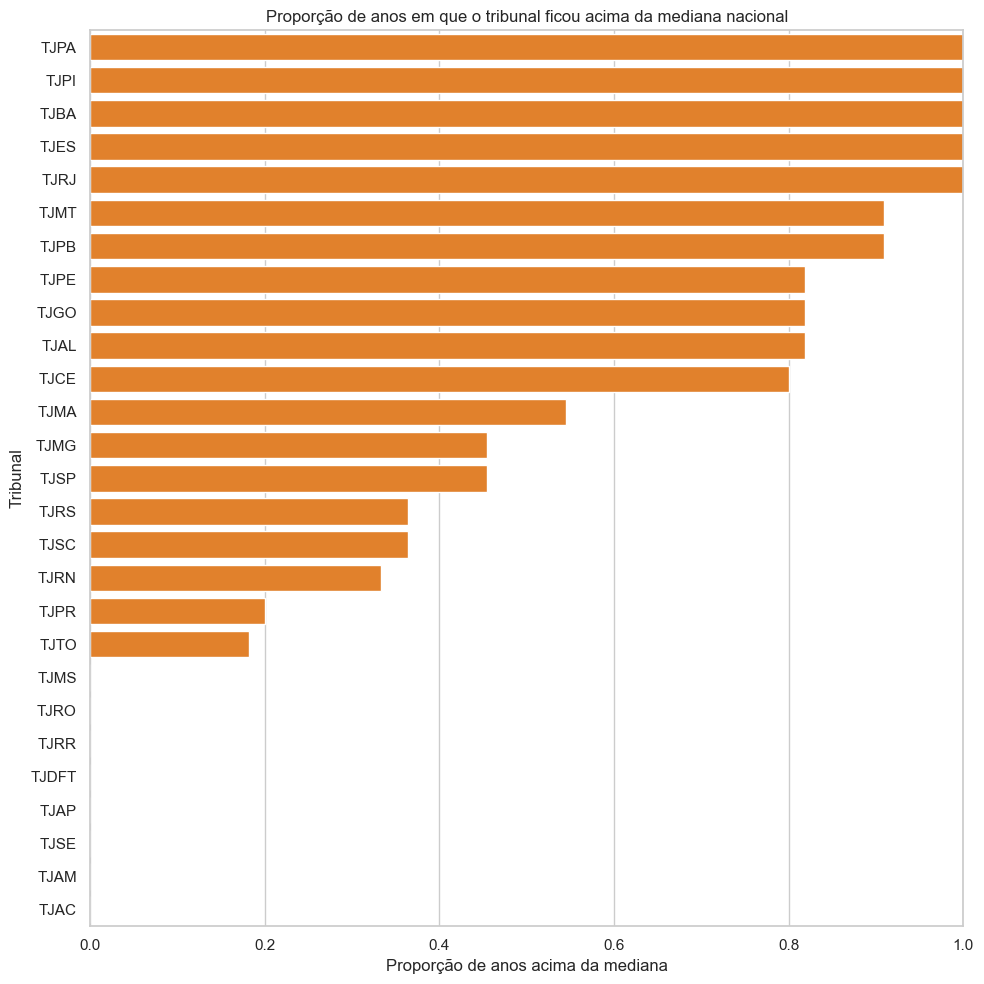

,sigla,proporcao_anos_acima
13,TJPA,1.00
16,TJPI,1.00
4,TJBA,1.00
7,TJES,1.00
18,TJRJ,1.00
12,TJMT,0.91
14,TJPB,0.91
15,TJPE,0.82
8,TJGO,0.82
1,TJAL,0.82


In [9]:
# Calcula a mediana nacional de cada ano
mediana_ano = (
    df.groupby("ano")["tempo_baixa"]
      .median()
      .rename("mediana_nacional")
      .reset_index()
)

# Junta a mediana nacional à base original
df_comparacao = df.merge(mediana_ano, on="ano")

# Cria indicador: 1 se o tribunal está acima da mediana nacional no ano
df_comparacao["acima_mediana"] = (
    df_comparacao["tempo_baixa"] > df_comparacao["mediana_nacional"]
).astype(int)

# Calcula a proporção de anos acima da mediana para cada tribunal
persistencia = (
    df_comparacao.groupby("sigla")["acima_mediana"]
      .mean()
      .reset_index()
      .rename(columns={"acima_mediana": "proporcao_anos_acima"})
)

# Ordena pelos tribunais que mais frequentemente ficaram acima da mediana
persistencia = persistencia.sort_values("proporcao_anos_acima", ascending=False)

# Gráfico
plt.figure(figsize=(10, 10))
sns.barplot(
    data=persistencia,
    x="proporcao_anos_acima",
    y="sigla",
    color="#ff7f0e"
)
plt.title("Proporção de anos em que o tribunal ficou acima da mediana nacional")
plt.xlabel("Proporção de anos acima da mediana")
plt.ylabel("Tribunal")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

# Exibe os dez tribunais com maior persistência acima da mediana
persistencia.head(10).round(2)

**Leitura:** um valor próximo de 1 indica que o tribunal ficou acima da mediana nacional em quase todos os anos. Um valor próximo de 0 indica que ficou abaixo da mediana na maior parte do período.

## 9. Relação com capacidade institucional

Para compreender parte das diferenças, serão examinadas correlações entre o tempo de tramitação e alguns indicadores estruturais.

A correlação mede a força e a direção de uma associação linear. Ela **não demonstra causalidade**.


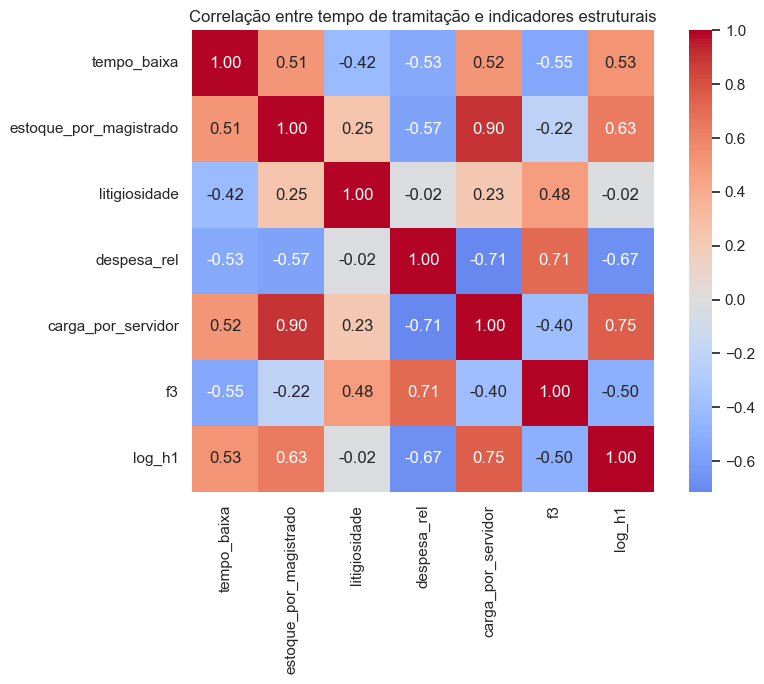

tempo_baixa               1.00
log_h1                    0.53
carga_por_servidor        0.52
estoque_por_magistrado    0.51
litigiosidade            -0.42
despesa_rel              -0.53
f3                       -0.55
Name: tempo_baixa, dtype: float64

In [10]:
# Seleciona as variáveis para análise de correlação
variaveis_correlacao = [
    "tempo_baixa",
    "estoque_por_magistrado",
    "litigiosidade",
    "despesa_rel",
    "carga_por_servidor",
    "f3",
    "log_h1"
]

# Calcula a matriz de correlação
correlacoes = df[variaveis_correlacao].corr()

# Gráfico de calor das correlações
plt.figure(figsize=(9, 7))
sns.heatmap(
    correlacoes,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)
plt.title("Correlação entre tempo de tramitação e indicadores estruturais")
plt.tight_layout()
plt.show()

# Correlações específicas com o tempo de tramitação
correlacoes["tempo_baixa"].sort_values(ascending=False).round(2)

**Leitura:** valores próximos de 1 indicam associação positiva; valores próximos de -1 indicam associação negativa; valores próximos de 0 indicam associação linear fraca. Correlação não significa que uma variável causa a outra.

## 10. Narrativa analítica

A análise começa pela trajetória nacional do tempo médio até a baixa. Se a mediana nacional caiu, isso indica melhora geral no período.

Contudo, a queda nacional pode esconder diferenças importantes entre os estados. Por isso, a análise examinou a variação de cada tribunal e a frequência com que cada um permaneceu acima da mediana nacional.

A narrativa proposta é a seguinte:

1. **Contexto:** a razoável duração do processo é um direito fundamental.
2. **Conflito:** a melhora nacional pode não ter alcançado todos os tribunais da mesma forma.
3. **Evidência:** a variação percentual e a persistência acima da mediana revelam desigualdades entre estados.
4. **Encaminhamento:** indicadores públicos podem apoiar o monitoramento, a alocação de recursos e o planejamento da gestão judiciária.

## 11. Storytelling para o relatório

**Título sugerido:**  
**A queda nacional da morosidade alcançou todos os estados?**

**Início:**  
Entre 2015 e 2025, o tempo médio até a baixa dos processos não criminais de primeiro grau apresentou mudanças importantes na Justiça Estadual brasileira.

**Problema:**  
A média nacional pode melhorar, mas isso não garante que todos os cidadãos tenham experimentado a mesma redução de espera.

**Conflito:**  
Alguns tribunais reduziram expressivamente o tempo de tramitação, enquanto outros permaneceram acima da mediana nacional por vários anos.

**Evidência:**  
A análise da variação percentual e da persistência acima da mediana mostra que a melhora não foi uniforme.

**Encaminhamento:**  
O acompanhamento público desses indicadores pode apoiar decisões de gestão, planejamento de pessoal e priorização do primeiro grau.

## 12. Accountability e governança

Os dados do Justiça em Números são públicos e permitem que sociedade, imprensa, órgãos de controle e gestores acompanhem o desempenho dos tribunais.

Essa transparência contribui para a accountability porque permite perguntar:

- Quais tribunais permanecem acima da mediana nacional?
- A redução da morosidade foi generalizada ou concentrada?
- Quais indicadores estruturais estão associados a maiores tempos de espera?
- As políticas de priorização do primeiro grau produziram resultados semelhantes em todos os estados?

Porém, o uso de rankings exige cautela. Um tribunal pode apresentar tempo maior porque atende população maior, demanda mais complexa ou possui mais processos antigos. Portanto, o tempo até a baixa deve ser analisado junto com carga, capacidade institucional e contexto territorial.

## 13. Limitações

- A base é observacional e não permite concluir causalidade.
- As observações de um mesmo tribunal ao longo dos anos não são independentes.
- O tempo médio até a baixa não mede qualidade das decisões judiciais.
- Diferenças entre tipos de processos não criminais podem influenciar o resultado.
- Valores extremos podem afetar médias e correlações.

## 14. Conclusão preliminar

O projeto busca verificar se a queda nacional da morosidade foi acompanhada por melhora semelhante em todos os estados. A resposta depende da comparação entre a trajetória nacional e a evolução de cada tribunal.

Se alguns tribunais permanecerem acima da mediana nacional por muitos anos, a conclusão será de que a melhora agregada conviveu com desigualdades territoriais persistentes.


## 15. Referências

BRASIL. Constituição da República Federativa do Brasil de 1988, art. 5º, LXXVIII.

CONSELHO NACIONAL DE JUSTIÇA. **Justiça em Números 2026**. Brasília, DF: CNJ, 2026.

MORETTIN, Pedro Alberto; SINGER, Júlio da Motta. **Estatística e ciência de dados**. 2. ed. Rio de Janeiro: LTC, 2022.

WICHMANN, Roberta Moreira. **Projeto Integrado de Ciência de Dados no Setor Público**: orientações do trabalho final. Brasília, DF: IDP, 2026.
